In [19]:
from leo_utils import arc_point_on_earth, compute_satellite_intersection_point_enu, compute_az_el_dist
import numpy as np
import json, gc, pandas as pd
from datetime import datetime
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import importlib, minmax_solvers
importlib.reload(minmax_solvers)
from minmax_solvers import solve_game_bestresp_Q0_then_Q1
from numpy.linalg import cholesky, solve, eigh
from Joint_waterfilling import (
    apply_precoder_to_cir,
    dominant_precoder_from_cir,
    joint_waterfilling_from_cir,
)

# Physical constants and power settings.
c = 3e8  # speed of light (m/s)
fc = 10e9  # carrier frequency (Hz)
wavelength = c / fc
tx_power_dbm = 50
jam_power_dbm = 70
k = 1.38e-23  # Boltzmann constant
GT = 13
La = 5

# Delay-Doppler experiment settings.
bandwidth = 200e6
Nfft = 1024
Tfft = Nfft / bandwidth
delay_search_max_s = 1e-3
delay_grid_blocks = np.arange(-200, 201, dtype=int)

# IMPORTANT:
# For delay-Doppler estimation over FFT blocks, the observation length must be
# longer than the largest searched relative delay. The previous setting used
# only ~8 blocks, which cannot support a delay search over [-200, 200].
search_num_blocks = max(512, int(2 * np.max(np.abs(delay_grid_blocks)) + 64))
search_observation_time_s = search_num_blocks * Tfft
# In the current two-satellite setup, the relative Doppler is much smaller than
# the absolute Doppler on each individual link. Therefore we search a finer
# relative-Doppler grid directly.
doppler_search_max_hz = 20e3
doppler_grid_step_hz = 1e3
doppler_grid_hz = np.arange(
    -doppler_search_max_hz,
    doppler_search_max_hz + doppler_grid_step_hz,
    doppler_grid_step_hz,
    dtype=float,
)

# Sionna channel time sampling.
# This is only used to generate Doppler-aware channels / geometry.
# cir_sampling_frequency > 2 * max_abs_doppler
cir_sampling_frequency = 3.0 / Tfft
cir_time_step_s = 1.0 / cir_sampling_frequency
doppler_num_time_steps = max(40, int(np.ceil(search_observation_time_s * cir_sampling_frequency)))
cir_observation_time_s = doppler_num_time_steps / cir_sampling_frequency

GT_linear_inv = 10 ** (-GT / 10)
La_linear = 10 ** (La / 10)
noise_power_watt = k * bandwidth * GT_linear_inv * La_linear
Tx_power_watt = 10 ** ((tx_power_dbm - 30) / 10)
Jam_power_watt = 10 ** ((jam_power_dbm - 30) / 10)
T_sys = 150.0
N0 = k * bandwidth * T_sys * La_linear
P0 = Tx_power_watt
P1 = Jam_power_watt


In [20]:
from sionna.rt import Receiver, Transmitter, PlanarArray, PathSolver, load_scene
import numpy as np
import vsat_dish_3gpp


def _as_2d_positions(rx_pos):
    rx_pos = np.asarray(rx_pos, dtype=float)
    if rx_pos.ndim == 1:
        if rx_pos.shape[0] != 3:
            raise ValueError("rx_pos must have shape (3,) or (K, 3)")
        rx_pos = rx_pos[None, :]
    if rx_pos.ndim != 2 or rx_pos.shape[1] != 3:
        raise ValueError("rx_pos must have shape (3,) or (K, 3)")
    return rx_pos


def _broadcast_velocity(velocity, count, name):
    if velocity is None:
        return np.zeros((count, 3), dtype=float)

    velocity = np.asarray(velocity, dtype=float)
    if velocity.ndim == 1:
        if velocity.shape[0] != 3:
            raise ValueError(f"{name} must have shape (3,) or ({count}, 3)")
        velocity = np.repeat(velocity[None, :], count, axis=0)

    if velocity.ndim != 2 or velocity.shape != (count, 3):
        raise ValueError(f"{name} must have shape (3,) or ({count}, 3)")
    return velocity


def compute_paths(tx_pos, rx_pos, tx_array, rx_array, tx_look_at, rx_look_at=None,
                  frequency=10e9, tx_velocity=None, rx_velocities=None,
                  max_depth=0, los=True, respect_rx_look_at=False):
    """
    Solve paths from one transmitter to one or more receivers.

    Doppler is controlled through tx/rx velocities. To obtain a time-varying
    CIR, call ``compute_cir(..., num_time_steps>1, sampling_frequency=...)``.

    Args:
        tx_pos:            (3,) transmitter position
        rx_pos:            (3,) or (K, 3) receiver positions
        tx_velocity:       (3,) transmitter velocity in ENU [m/s]
        rx_velocities:     (3,) or (K, 3) receiver velocities in ENU [m/s]
        respect_rx_look_at:
            False keeps the notebook's current RX pointing behavior.
            True makes each RX call ``look_at(rx_look_at)``.

    Returns:
        paths: Sionna RT ``Paths`` object
    """
    tx_pos = np.asarray(tx_pos, dtype=float)
    if tx_pos.shape != (3,):
        raise ValueError("tx_pos must have shape (3,)")

    rx_pos = _as_2d_positions(rx_pos)
    tx_velocity = _broadcast_velocity(tx_velocity, 1, "tx_velocity")[0]
    rx_velocities = _broadcast_velocity(rx_velocities, rx_pos.shape[0], "rx_velocities")

    scene = load_scene()
    scene.frequency = frequency
    scene.synthetic_array = True

    for tx_name in list(scene.transmitters):
        scene.remove(tx_name)
    for rx_name in list(scene.receivers):
        scene.remove(rx_name)

    scene.tx_array = tx_array
    tx = Transmitter(name="tx", position=tx_pos, display_radius=200)
    scene.add(tx)

    if isinstance(tx_look_at, str) and tx_look_at.lower() in ["up-z", "up", "z"]:
        tx_look_at = tx_pos + np.array([0.0, 0.0, 1.0])
    tx.look_at(tx_look_at)
    tx.velocity = tx_velocity.tolist()

    earth_radius_m = 6371e3
    legacy_rx_look_at = np.array([0.0, 0.0, -1.0 * earth_radius_m / 2.0])

    scene.rx_array = rx_array
    for i, (rx_pos_i, rx_vel_i) in enumerate(zip(rx_pos, rx_velocities)):
        rx = Receiver(name=f"rx{i}", position=rx_pos_i)
        scene.add(rx)
        if respect_rx_look_at and rx_look_at is not None:
            rx.look_at(rx_look_at)
        else:
            rx.look_at(legacy_rx_look_at)
        rx.velocity = rx_vel_i.tolist()

    solver = PathSolver()
    paths = solver(scene=scene,
                   max_depth=max_depth,
                   los=los,
                   synthetic_array=True)
    return paths


def compute_cir(tx_pos, rx_pos, tx_array, rx_array, tx_look_at, rx_look_at,
                frequency=10e9, tx_velocity=None, rx_velocities=None,
                sampling_frequency=1.0, num_time_steps=1,
                normalize_delays=False, max_depth=0, los=True,
                respect_rx_look_at=False, return_paths=False):
    """
    Compute CIR from one transmitter to one or more receivers.

    When ``num_time_steps > 1`` and non-zero velocities are provided, ``a_all``
    contains the Doppler phase evolution across the last axis.

    Returns:
        a_all: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps]
        tau_all: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths]
    """
    paths = compute_paths(
        tx_pos=tx_pos,
        rx_pos=rx_pos,
        tx_array=tx_array,
        rx_array=rx_array,
        tx_look_at=tx_look_at,
        rx_look_at=rx_look_at,
        frequency=frequency,
        tx_velocity=tx_velocity,
        rx_velocities=rx_velocities,
        max_depth=max_depth,
        los=los,
        respect_rx_look_at=respect_rx_look_at,
    )

    a_all, tau_all = paths.cir(
        sampling_frequency=sampling_frequency,
        num_time_steps=num_time_steps,
        normalize_delays=normalize_delays,
        out_type="numpy",
    )

    if return_paths:
        return a_all, tau_all, paths
    return a_all, tau_all

jam_rows =6
jam_cols = 6
jam_antennas = jam_cols*jam_rows

sat_rows = 6
sat_cols = 6
sat_antennas = sat_cols*sat_rows

tx_rows = 6
tx_cols = 6
tx_antennas = tx_cols*tx_rows

tx_array = PlanarArray(num_rows=tx_rows, num_cols=tx_cols,
                        vertical_spacing=0.5, horizontal_spacing=0.5,
                        pattern="tr38901", polarization="V")
                        # pattern="iso", polarization="V")

jam_array = PlanarArray(num_rows=jam_rows, num_cols=jam_cols,  
                            vertical_spacing=0.5, horizontal_spacing=0.5,
                        #  pattern="vsat_dish",
                            pattern="tr38901",
                            polarization="V")

sat_array = PlanarArray(num_rows=sat_rows, num_cols=sat_cols,
                             vertical_spacing=0.5, horizontal_spacing=0.5,
                             pattern="tr38901",
                             polarization="V")

def collapse_channel(a_cir, t_idx=None):
    """
    Collapse channel tensor over the path axis.

    Input:
      a_cir: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps]

    Output:
      If t_idx is None:
          H_t: (M, N, num_time_steps)
      else:
          H_t: (M, N)

      where M = num_rx*num_rx_ant, N = num_tx*num_tx_ant.
    """
    nr, nra, nt, nta, npaths, ntimes = a_cir.shape

    H_t = a_cir.sum(axis=-2)  # sum over paths -> [nr, nra, nt, nta, ntimes]

    if t_idx is None:
        H_t = H_t.reshape(nr * nra, nt * nta, ntimes)
        return H_t

    assert 0 <= t_idx < ntimes
    H_slice = H_t[..., t_idx]
    H_slice = H_slice.reshape(nr * nra, nt * nta)
    return H_slice

In [21]:

""" We have a number of iterations > 1, 
so this function can "control" 
the evolution of the algorithm. The return is FALSE, if TRUE it will block the algorithm"""


def make_tqdm_progress(total, desc, position=1, leave=False):
    bar = tqdm(total=total, desc=desc, position=position,
                  leave=leave, dynamic_ncols=True, miniters=1, mininterval=0.0)
    bar.refresh()  
    last_i = 0

    def _cb(i=None, total=None, metrics=None, ctx=None):
        nonlocal last_i
        if i is not None:
            di = int(i) - int(last_i)     
            if di > 0:
                bar.update(di)
                last_i = i
        if metrics:
            show = {k: (f"{v:.3e}" if ("res" in k or "err" in k) else f"{v:.4f}")
                    for k, v in metrics.items()}
            bar.set_postfix(show, refresh=True)  
        return False

    _cb.close = bar.close
    return _cb

In [22]:

def make_tqdm_progress(total, desc, position=1, leave=False):
    bar = tqdm(total=total, desc=desc, position=position,
                  leave=leave, dynamic_ncols=True, miniters=1, mininterval=0.0)
    bar.refresh()  
    last_i = 0

    def _cb(i=None, total=None, metrics=None, ctx=None):
        nonlocal last_i
        if i is not None:
            di = int(i) - int(last_i)     
            if di > 0:
                bar.update(di)
                last_i = i
        if metrics:
            show = {k: (f"{v:.3e}" if ("res" in k or "err" in k) else f"{v:.4f}")
                    for k, v in metrics.items()}
            bar.set_postfix(show, refresh=True)  
        return False

    _cb.close = bar.close
    return _cb

In [23]:
# Load and make sure each time block is ordered by Rank (nearest first)
df = pd.read_csv("starlink_timeseries_5min_top5.csv")
df = df.sort_values(["Time", "Rank"], ascending=[True, True]).reset_index(drop=True)
n_steps = df["Time"].nunique()
print("Total steps:", n_steps)
# max_steps = 3
# print(df.head(max_steps*5))

Total steps: 30


In [25]:
# Generate TX positions on the ground

distances_km = [7]
azimuths_deg = np.linspace(0, 360, len(distances_km), endpoint=False)
gnd_positions = [np.array([0.0, 0.0, 0.0])]

for d_km, az in zip(distances_km, azimuths_deg):
    pos = arc_point_on_earth(d_km, az)
    gnd_positions.append(pos)
gnd_positions = np.array(gnd_positions)

for i, pos in enumerate(gnd_positions):
    print(f"TX{i}(m): {pos}")
    
# Generate Sats positions 
sat_orbit_m = 550e3
angles = [(117.88, 40),(230.22, 89.9)]
sat_positions = []
delays_ms = []
fspl_db = []
frequency_hz = 10e9 
wavelength = 3e8 / frequency_hz

for az, el in angles:
    pos, delay, dist = compute_satellite_intersection_point_enu(az, el, sat_orbit_m)
    sat_positions.append(pos)
    delays_ms.append(delay)
    fspl = 20 * np.log10(4 * np.pi * dist / wavelength)
    fspl_db.append(fspl)

sat_positions = np.array(sat_positions)
delays_ms = np.array(delays_ms)
fspl_db = np.array(fspl_db)

print("\nSatellite Pos [m]:\n", sat_positions)
print("\nPropagation delays [ms]:\n", delays_ms)
print("\nFree-space path loss [dB]:\n", fspl_db)

delay_max = np.max(delays_ms) - np.min(delays_ms)
print("\ndelay_max [ms]:\n", delay_max)
# Compute az/el/dist per TX-SAT

# for i, tx in enumerate(gnd_positions):
#     print(f"\nFrom TX{i}:")
#     for j, sat in enumerate(sat_positions):
#         az, el, dist, n_waves = compute_az_el_dist(sat, tx, frequency_hz)
#         print(f"  SAT{j}: az={az:.2f}°, el={el:.2f}°, dist={dist:.2f} m, λ count ≈ {n_waves:.2f}")
# csv_path = "starlink_timeseries_5min_all.csv"
# df_all = pd.read_csv(csv_path)

# vel_cols = ["vx_East (m/s)", "vy_North (m/s)", "vz_Up (m/s)"]
# speed_total_mps = np.sqrt((df_all[vel_cols].astype(float) ** 2).sum(axis=1))

# max_speed_idx = speed_total_mps.idxmax()
# max_speed_mps = speed_total_mps.loc[max_speed_idx]

# print("\\nMax total speed [m/s]:\\n", max_speed_mps)
# print(df_all.loc[max_speed_idx])

TX0(m): [0. 0. 0.]
TX1(m): [ 4.28626293e-13  6.99999859e+03 -3.84554976e+00]

Satellite Pos [m]:
 [[ 549873.55622635 -290897.35533001  521986.20344078]
 [   -737.71434142    -614.20427674  549999.93342946]]

Propagation delays [ms]:
 [2.70688791 1.8333359 ]

Free-space path loss [dB]:
 [170.63360274 167.24903815]

delay_max [ms]:
 0.8735520095230127


In [26]:
# ---- JSON 序列化器：支持 numpy / complex ----
class NumpyEncoder(json.JSONEncoder):
    def default(self, o):
        if isinstance(o, (np.integer,)):  return int(o)
        if isinstance(o, (np.floating,)): return float(o)
        if isinstance(o, (np.complexfloating, complex)):
            return {"__complex__":[float(o.real), float(o.imag)]}
        if isinstance(o, np.ndarray):     return o.tolist()
        return super().default(o)


def _select_groups(groups, run_steps):
    if isinstance(run_steps, str):
        if run_steps.lower() != "all":
            raise ValueError("run_steps must be an integer or 'all'")
        return groups

    run_steps = int(run_steps)
    if run_steps <= 0:
        raise ValueError("run_steps must be positive")
    return groups[:run_steps]


def _select_topk(group_df, topk):
    group_df = group_df.sort_values("Rank").copy()
    if isinstance(topk, str):
        if topk.lower() != "all":
            raise ValueError("topk must be an integer or 'all'")
        return group_df

    topk = int(topk)
    if topk <= 0:
        raise ValueError("topk must be positive")
    return group_df.head(topk).copy()


def synthesize_tx_bf_from_precoder(W_t):
    """Collapse W_t into one unit-norm TX beam vector using all streams."""
    if W_t is None:
        return None

    W_t = np.asarray(W_t, dtype=complex)
    if W_t.ndim == 1:
        w_t = W_t.reshape(-1, 1)
    elif W_t.ndim == 2:
        if W_t.shape[1] == 0:
            return np.zeros((W_t.shape[0], 1), dtype=complex)
        stream_weights = np.ones((W_t.shape[1], 1), dtype=complex) / np.sqrt(W_t.shape[1])
        w_t = W_t @ stream_weights
    else:
        raise ValueError(f"W_t must be a vector or matrix, got shape {W_t.shape}.")

    norm_w = np.linalg.norm(w_t)
    if norm_w > 0:
        w_t = w_t / norm_w
    return w_t


run_steps = 1  # int or "all"
topk = 2       # int or "all"
out_path = "doppler_a_tx_tau_tx.jsonl"
overwrite_output = True

# Precoding options:
#   "off"                -> keep the raw a_tx only
#   "dominant"           -> dominant right-singular-vector precoder from a_tx
#   "joint_waterfilling" -> full water-filling precoder from a_tx using N0/P0
precoder_mode = "joint_waterfilling"
precoder_num_streams = None
precoder_t_idx = 0
save_precoded_cir = True

# Sionna channel sampling configuration is defined in the first cell.
tx_velocity_vec = np.array([0.0, 0.0, 0.0])
jam_velocity_vec = np.array([0.0, 0.0, 0.0])

groups = list(df.sort_values(["Time", "Rank"]).groupby("Time"))
groups_to_run = _select_groups(groups, run_steps)
total_steps = len(groups_to_run)

buffer = []
FLUSH_EVERY = 1
file_mode = "w" if overwrite_output else "a"
f_out = open(out_path, file_mode, encoding="utf-8")

for step_idx, (t, g) in enumerate(tqdm(groups_to_run, desc="Processing steps"), start=1):
    gk = _select_topk(g, topk)
    if gk.empty:
        continue

    sat_positions = gk[["x_East (m)", "y_North (m)", "z_Up (m)"]].to_numpy()
    sat_velocities = gk[["vx_East (m/s)", "vy_North (m/s)", "vz_Up (m/s)"]].to_numpy()
    names = gk["Name"].tolist()

    # a: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps]
    # tau: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths]
    a_tx, tau_tx = compute_cir(
        gnd_positions[0],
        sat_positions,
        tx_array,
        sat_array,
        np.array(gnd_positions[0]) + np.array([0.0, 0.0, 100.0]),
        gnd_positions[0],
        tx_velocity=tx_velocity_vec,
        rx_velocities=sat_velocities,
        sampling_frequency=cir_sampling_frequency,
        num_time_steps=doppler_num_time_steps,
        normalize_delays=False,
    )

    precoder_result = None
    if precoder_mode == "dominant":
        precoder_result = dominant_precoder_from_cir(
            a_tx,
            t_idx=precoder_t_idx,
            num_streams=precoder_num_streams,
            use_precoding=True,
        )
    elif precoder_mode == "joint_waterfilling":
        precoder_result = joint_waterfilling_from_cir(
            a_tx,
            N0=N0,
            P0=P0,
            t_idx=precoder_t_idx,
            num_streams=precoder_num_streams,
            use_precoding=True,
        )
    elif precoder_mode != "off":
        raise ValueError(
            f"Unsupported precoder_mode={precoder_mode!r}. "
            "Use 'off', 'dominant', or 'joint_waterfilling'."
        )

    W_t = precoder_result["W_t"] if precoder_result is not None else None
    Q_t = precoder_result.get("Q_t") if precoder_result is not None else None
    if Q_t is None and W_t is not None:
        Q_t = W_t @ W_t.conj().T
    w_t = synthesize_tx_bf_from_precoder(W_t)
    active_modes = precoder_result.get("active_modes") if precoder_result is not None else None
    rate_bpcu = precoder_result.get("rate_bpcu") if precoder_result is not None else None
    a_eff = (
        apply_precoder_to_cir(a_tx, w_t, use_precoding=True)
        if (w_t is not None and save_precoded_cir)
        else None
    )
    entry = {
        "a_tx": a_tx,
        "a_eff": a_eff,
        "tau_tx": tau_tx,
        "W_t": W_t,
        "Q_t": Q_t,
        "w_t": w_t,
        "w_t_synthesis": "equal_stream_sum_unit_norm",
        "precoder_mode": precoder_mode,
        "precoder_num_streams": precoder_num_streams,
        "precoder_t_idx": precoder_t_idx,
        "precoder_active_modes": active_modes,
        "precoder_rate_bpcu": rate_bpcu,
        "use_precoding": bool(a_eff is not None),
    }
    buffer.append(entry)

    if (step_idx % FLUSH_EVERY == 0) or (step_idx == total_steps):
        for e in buffer:
            f_out.write(json.dumps(e, cls=NumpyEncoder) + "\n")
        f_out.flush()
        buffer.clear()
        gc.collect()
        print(
            f"[flush] wrote up to step {step_idx}/{total_steps} "
            f"(precoder_mode={precoder_mode}, use_precoding={a_eff is not None})"
        )

f_out.close()
print(f"✅ Doppler-aware TX CIR saved to {out_path}")

Processing steps:   0%|          | 0/1 [00:00<?, ?it/s]

[flush] wrote up to step 1/1 (precoder_mode=joint_waterfilling, use_precoding=True)
✅ Doppler-aware TX CIR saved to doppler_a_tx_tau_tx.jsonl


SPS=3  relative delay=266.47 samples (88.82 blocks)  relative Doppler=-7.876 kHz  gamma0=8.98 dB  gamma1=4.78 dB
N=1536 observed samples, N_v=1222 valid samples, M=5.3e+04 cells
gamma0=-25.00 dB | INR [dB] [-27.8 -26.7 -26.7 -26.7 -26.6 -26.6] | Pwrong [0. 1. 1. 1. 1. 1.] | MFlop [  0.  371.5  30.   30.   30.   30. ]   (12s)
gamma0=-20.00 dB | INR [dB] [-23.5 -21.8 -21.7 -21.7 -21.7 -21.7] | Pwrong [0. 1. 1. 1. 1. 1.] | MFlop [  0.  371.5  30.   30.   30.   30. ]   (24s)
gamma0=-15.00 dB | INR [dB] [-21.1 -16.9 -16.8 -16.8 -16.8 -16.8] | Pwrong [0. 1. 1. 1. 1. 1.] | MFlop [  0.  371.5  30.   30.   30.   30. ]   (36s)
gamma0=-12.50 dB | INR [dB] [-21.7 -14.5 -14.5 -14.5 -14.5 -14.5] | Pwrong [0. 1. 1. 1. 1. 1.] | MFlop [  0.  371.5  30.   30.   30.   30. ]   (50s)
gamma0=-10.00 dB | INR [dB] [-22.9 -12.3 -12.3 -12.3 -12.3 -12.3] | Pwrong [0.   0.98 0.99 0.99 0.99 1.  ] | MFlop [  0.  371.5  30.   30.   30.   30. ]   (64s)
gamma0= -9.00 dB | INR [dB] [-23.4 -11.8 -11.7 -11.7 -11.6 -11.6]

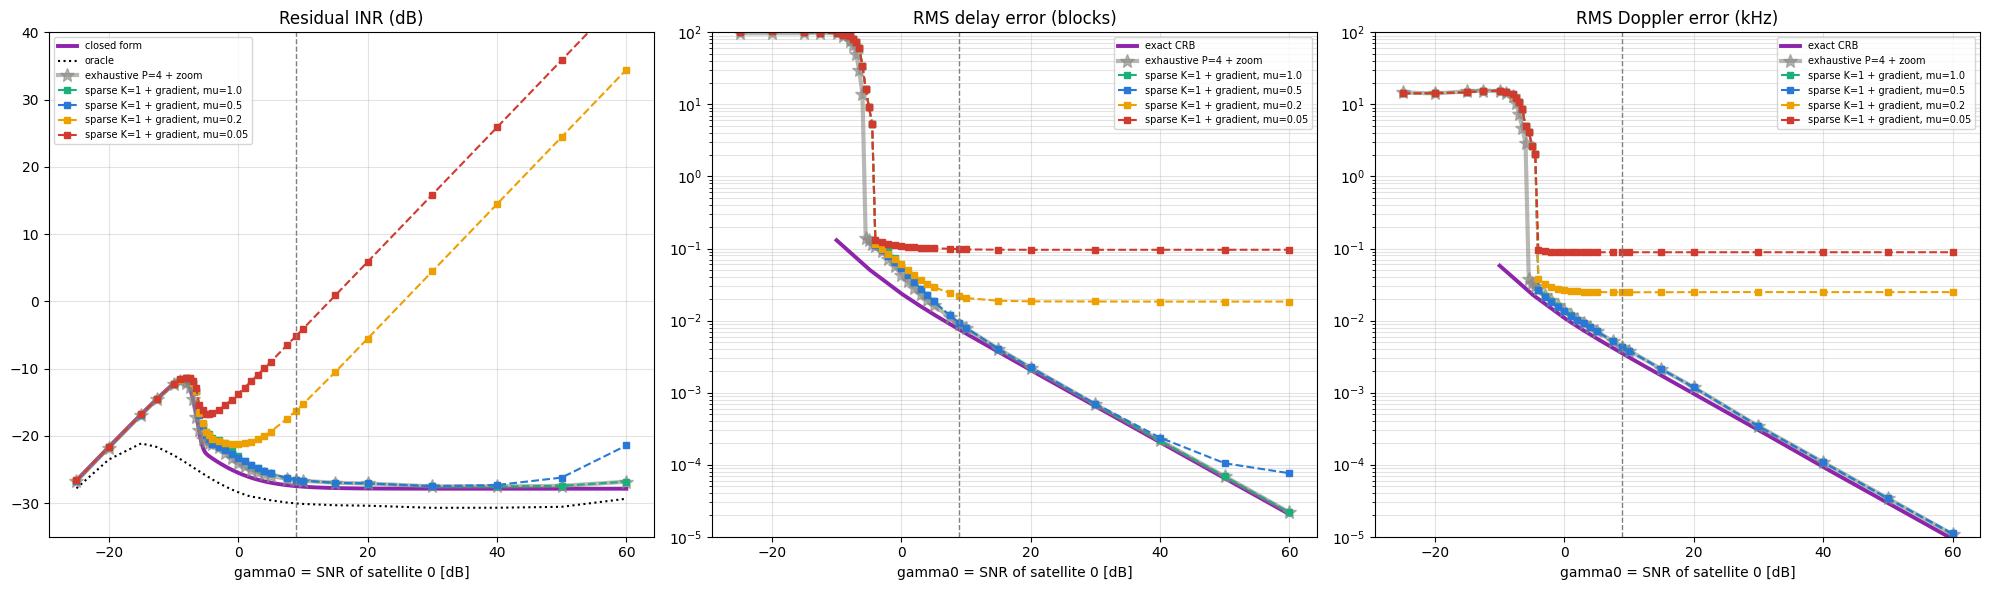

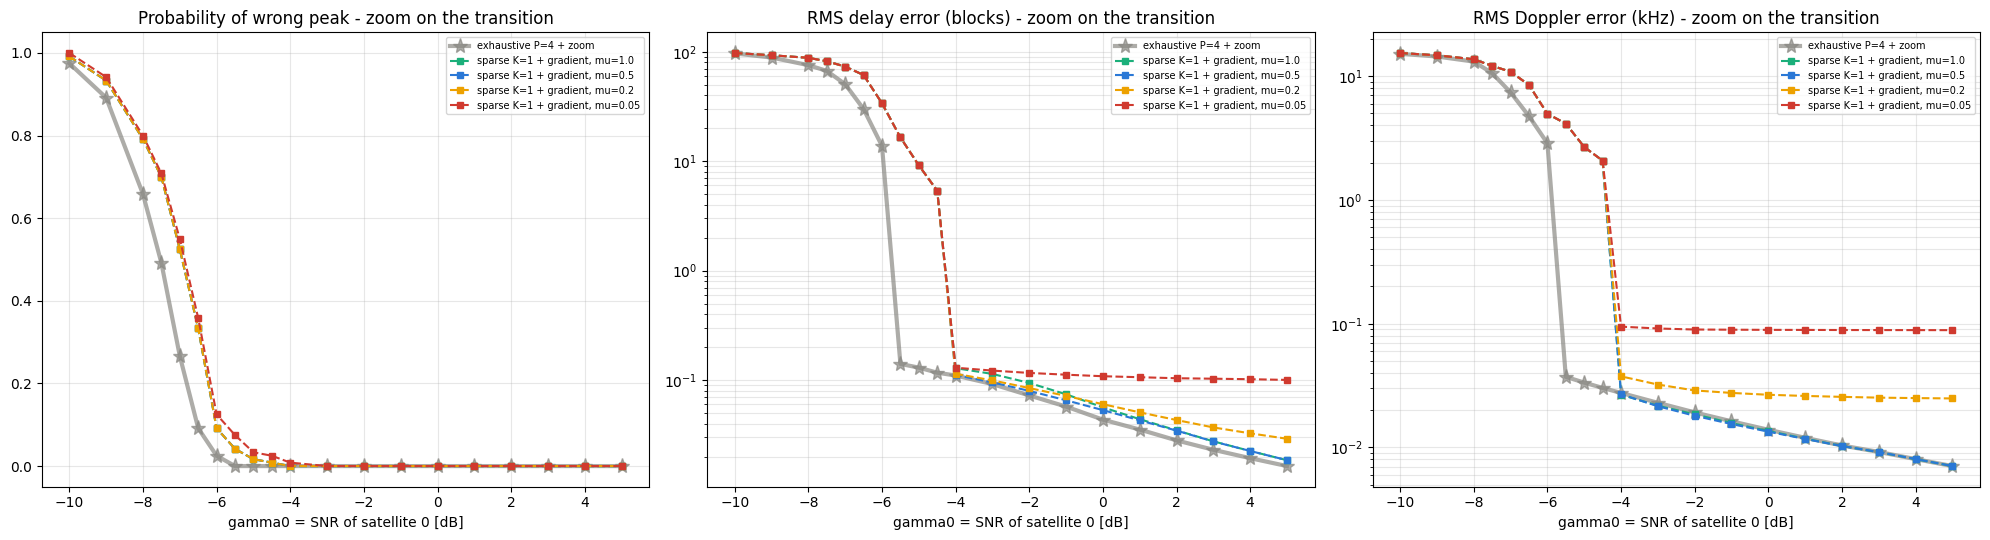

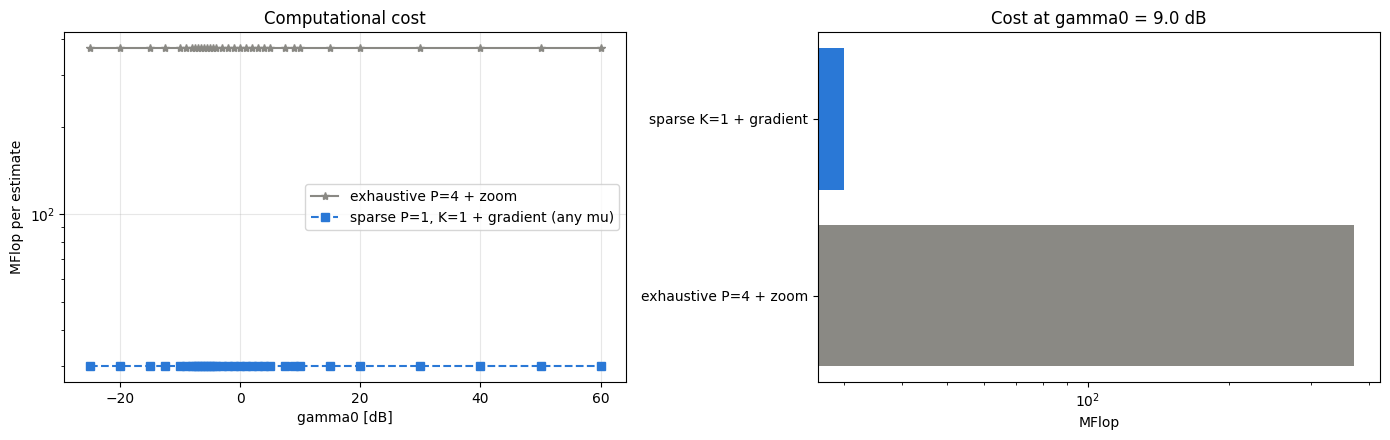

In [33]:
# --- Relative delay-Doppler estimation over the two received satellite signals ---
# Run the notebook from top to bottom. This cell reuses the global imports,
# constants, and search settings defined in the previous cells.


# =====================================================================================================
# CELL: Monte-Carlo of the nuller (exhaustive search P=4 + zoom  vs  sparse P=1, K=1 + fixed-step gradient)
#        INR vs gamma with closed form, RMS delay/Doppler with exact CRB, computational complexity.
# Paste AFTER the setup and channel-generation cells (it only uses the notebook variables:
#   a_eff, tau_tx, sat_positions, sat_velocities, fc, k, bandwidth, T_sys, La, tx_power_dbm, Tfft, N0).
# It reads no files: the channel is the notebook's (a_eff, MRC at time t=0 as in build_satellite_link_table).
# Dependencies: numpy, scipy, matplotlib.   Run time: ~0.3 s per trial (about 10 minutes with the default parameters).
# =====================================================================================================
import sys, types, time
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

# ------------------------------ SIMULATION PARAMETERS ------------------------------
N_TRIALS   = 100                                              # Monte-Carlo trials per point (quick test: 3); x3 above 30 dB, +20 in the transition
GAMMA0_DB  = [-25, -20, -15, -12.5, -10, -9, -8, -7.5, -7, -6.5, -6, -5.5, -5, -4.5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 7.5, 10, 15, 20, 30, 40, 50, 60]   # SNR of satellite 0 [dB] (dense grid in the RMS transition zone, where the exhaustive/sparse gap is visible); the 50 dBm value is added automatically
                                                                                 # (the flat low-SNR part and the threshold lie below 0 dB: points down to -25 are needed)
MUS        = (1.0, 0.5, 0.2, 0.05)                            # gradient step sizes (10 iterations, Newton-scaled)
SEED       = 95000
RUN_EXACT_CRB = False                                         # True: recompute the exact CRB (about 2 min per point)

# ------------------------------ CHANNEL FROM THE NOTEBOOK (replaces sionna_channel_io) ------------------------------
_A = np.asarray(a_eff, dtype=complex)[:, :, 0, 0, 0, :]       # (2 satellites, rx antennas, time steps) as in the notebook
_TAU = np.array([np.mean(np.asarray(tau_tx, dtype=float)[i]) for i in range(2)])   # mean delay per satellite (as tau_eff_s in the notebook)
_POS, _VEL = np.asarray(sat_positions, float)[:2], np.asarray(sat_velocities, float)[:2]
_T = _A.shape[-1]
_W = [_A[i, :, 0] / np.linalg.norm(_A[i, :, 0]) for i in range(2)]                     # MRC at time t=0
_G = np.array([np.conj(_W[i]) @ _A[i] for i in range(2)])                              # gains g_k[n]
_n = np.arange(_T)
_slope = np.array([np.polyfit(_n, np.unwrap(np.angle(_G[i])), 1)[0] / (2 * np.pi) for i in range(2)])
_FD = np.array([-(_VEL[i] @ _POS[i] / np.linalg.norm(_POS[i])) * fc / 299792458.0 for i in range(2)])
_SPS = int(round(_FD[0] / _slope[0] * Tfft)); _TS = Tfft / _SPS                       # samples per block (3)
_AMP = np.abs(_G[:, 0])
if _SPS < 2 or _T < 2 * 200 * _SPS + 36:
    raise RuntimeError(
        f"This model requires an oversampled CIR (>=2 samples per block) and at least 2*200*SPS+36 time steps: "
        f"found SPS={_SPS} and T={_T} time steps. With 1 sample per block the fractional delay (88.8 blocks) cannot be applied "
        f"to a full-band signal and even the oracle has an INR that grows with SNR. In cell 0 set "
        f"cir_sampling_frequency = 3.0 / Tfft (3 samples per block), regenerate the channel (cell 5) and rerun: "
        f"with search_num_blocks=512 this gives 1536 time steps.")
S = types.ModuleType("sionna_channel_io"); sys.modules["sionna_channel_io"] = S
S.__dict__.update(dict(A_EFF=_A, T=_T, TAU=_TAU, SPS=_SPS, TS=_TS, TFFT=Tfft, DK=(_TAU[1] - _TAU[0]) / _TS, F_REL=_slope[1] - _slope[0],
                       AMP=_AMP, GN=_G / _AMP[0], TX_DBM=tx_power_dbm, N0_W=N0))
S.GAMMA0_PHYS = 10 * np.log10(10 ** ((tx_power_dbm - 30) / 10) * _AMP[0] ** 2 / N0)
S.GAMMA1_PHYS = S.GAMMA0_PHYS + 20 * np.log10(_AMP[1] / _AMP[0])
print(f"SPS={S.SPS}  relative delay={S.DK:.2f} samples ({S.DK / S.SPS:.2f} blocks)  relative Doppler={S.F_REL / S.TS / 1e3:.3f} kHz  "
      f"gamma0={S.GAMMA0_PHYS:.2f} dB  gamma1={S.GAMMA1_PHYS:.2f} dB")

GAMMA0_DB = sorted(set(GAMMA0_DB) | {round(float(S.GAMMA0_PHYS), 2)})       # includes the physical point at 50 dBm
# ------------------------------ MODULES (code identical to the validated one) ------------------------------
_SRC = {
    "nuller_sim_lin": r'''"""
NON-CIRCULAR model: finite observation window of N samples, arbitrary (continuous) Dopplers f0, f1.

  y0[n] = x(n - k0) e^{j 2 pi f0 n} + d0[n]      n = 0..N-1  (central window of a long sequence of NL = N + 2 MG samples)
  y1[n] = e^{j .7} x(n - k1) e^{j 2 pi f1 n} + d1[n]
  relative: dk = k1 - k0 (delay), df = f1 - f0 (Doppler);  the search estimates tau = -dk, f = df.

Differences with respect to the circular model:
  * generation: delays (band-limited shifts) applied to the long sequence, then a window of N samples:
    no wrap inside the window, exact delays and Dopplers, arbitrary f0;
  * search metric: LINEAR correlation (zero-padding to 2N) instead of circular;
  * alignment: fractional shift with zero-padding to 2N; invalid samples are discarded
    (|tau_hat| per side + EDGE margin for edge ripple): N_v = N - 2 EDGE - |tau_hat| useful samples;
  * the signal has GUARD null bins per side (oversampled, realistic physical assumption).
Closed-form formulas unchanged with N -> N_v.
"""
import numpy as np

# ============================================================== PARAMETERS
N = 512                       # 512 observed blocks (search_num_blocks of the notebook)
MG = 160                      # margin samples per side in the generation (> maximum delay 10 + filter)
NL = N + 2 * MG
GUARD = 43                    # null bins per side out of NL bins (~5.2% of the band): needed by the FIR delay filter
EDGE = 32                     # samples discarded per side besides those invalidated by the shift
N0 = 1.0
H0 = 1.0 + 0j
H1 = np.exp(1j * 0.7)
K0_MAX = 10.0                 # delay of each antenna uniform in [-10, 10] samples
K_TRUE_MAX = 2 * K0_MAX       # relative |dk| <= 20 (triangular)
K_MAX = 200                    # the search covers [-22, 22]
F0_MAX = 2.5 / N              # Doppler of each antenna uniform in [-2.5, 2.5] bins (continuous!)
FD_MAX = 2 * F0_MAX           # relative |df| <= 5 bins
F_GRID_MAX = 20e3 * 5.12e-6          # the search covers [-6, 6] bins
ZOOM_STAGES, ZOOM_RATIO, ZOOM_HALF = 6, 4, 4
SEED = 4321
RNG = np.random.default_rng(SEED)
NIDX = np.arange(N)
KL = np.fft.fftfreq(NL, d=1.0 / NL)                   # bins of the long sequence
K2 = np.fft.fftfreq(2 * N, d=1.0 / (2 * N)).astype(int)   # integer bins of the 2N FFT
KP = K2.astype(float)


def cgauss(var, size):
    return np.sqrt(var / 2.0) * (RNG.standard_normal(size) + 1j * RNG.standard_normal(size))


# ============================================================== MODEL
def signal_long(var, size):
    """Band-limited x (GUARD null bins per side) over NL samples, power per sample = var."""
    X = np.fft.fft(cgauss(1.0, size), axis=-1)
    mask = (np.abs(KL) < NL // 2 - GUARD).astype(float)
    return np.fft.ifft(X * mask, axis=-1) * np.sqrt(var / mask.mean())


def _window(X, k, f):
    """From the long spectrum X: delay k (continuous), central window, Doppler f."""
    xs = np.fft.ifft(X * np.exp(-2j * np.pi * KL * k / NL), axis=-1)[..., MG:MG + N]
    return xs * np.exp(2j * np.pi * f * NIDX)


class Channel:
    def __init__(self, k0, f0, k1, f1):
        self.k0, self.f0, self.k1, self.f1 = k0, f0, k1, f1
        self.dk = k1 - k0
        self.df = f1 - f0


TFFT = 1024 / 200e6                                   # duration of a block (5.12 us) = one sample of the model
LINK = dict(tau_s=(1.296396e-3, 1.751171e-3), fd_hz=(67.929079e3, 60.058955e3), alpha_abs=(3.215599e-07, 1.982862e-07))   # output of notebook cell 9


def draw_channel():
    """Fixed geometry (Sionna, 2 satellites): relative delay and relative Doppler from the notebook; only data and noise are random."""
    k0 = 0.0; k1 = (LINK["tau_s"][1] - LINK["tau_s"][0]) / TFFT
    f0 = 0.0                                              # absolute Doppler of the reference link assumed already removed (only the relative one matters)
    return Channel(k0, f0, k1, f0 + (LINK["fd_hz"][1] - LINK["fd_hz"][0]) * TFFT)


def receive_block(ex, ch):
    X = np.fft.fft(signal_long(ex, NL))
    y0 = H0 * _window(X, ch.k0, ch.f0) + cgauss(N0, N)
    y1 = H1 * _window(X, ch.k1, ch.f1) + cgauss(N0, N)
    return y0, y1


def tests_vec(ex, ch, n_test):
    """Test blocks: signal part ONLY (no noise). The output noise is computed in closed form
    (inr_vec): this removes the measurement variance due to noise, which is much larger than the residual INR."""
    X = np.fft.fft(signal_long(ex, (n_test, NL)), axis=1)
    return H0 * _window(X, ch.k0, ch.f0), H1 * _window(X, ch.k1, ch.f1)


# ============================================================== EXHAUSTIVE SEARCH VIA FFT (linear correlation)
class FFTSearch:
    def __init__(self, P):
        self.P = P
        self.Q = 2 * P * N
        n_all = np.arange(-K_MAX * P, K_MAX * P + 1)
        self.tau = n_all / P
        self.sel = n_all % self.Q
        m = int(round(F_GRID_MAX * N * P))
        self.jj = np.arange(-m, m + 1)
        self.f = self.jj / (P * N)
        self.zidx = (P * K2[None, :] + 2 * self.jj[:, None]) % self.Q
        self.pad = K2 % self.Q

    @staticmethod
    def spec0(y0):
        return np.fft.fft(y0, 2 * N)

    def metric(self, Y0F, y1):
        """|S(tau, f)|^2 with S = sum_m y0[m+tau] conj(y1[m]) e^{j 2 pi f m} (sum over the window samples only)."""
        Z = np.fft.fft(y1, self.Q)
        X = Y0F[None, :] * np.conj(Z[self.zidx])
        Xp = np.zeros((len(self.jj), self.Q), dtype=complex)
        Xp[:, self.pad] = X
        r = np.fft.ifft(Xp, axis=1)[:, self.sel] * self.P
        return np.abs(r) ** 2

    def estimate(self, Y0F, y1):
        M = self.metric(Y0F, y1)
        jf, ik = np.unravel_index(np.argmax(M), M.shape)
        return self.tau[ik], self.f[jf]


def metric_direct(y0, y1, taus, fs):
    """Reference: explicit correlation with the same zero-padding shift. (n_tau, n_f)."""
    Y0F = np.fft.fft(y0, 2 * N)
    out = np.empty((len(taus), len(fs)))
    for i, t in enumerate(taus):
        y0s = np.fft.ifft(Y0F * np.exp(2j * np.pi * KP * t / (2 * N)))[:N]
        for j, f in enumerate(fs):
            out[i, j] = np.abs(np.sum(y0s * np.conj(y1) * np.exp(2j * np.pi * f * NIDX))) ** 2
    return out


def zoom_refine(Y0F, y1, tc, fc, dt, df):
    for _ in range(ZOOM_STAGES):
        dt, df = dt / ZOOM_RATIO, df / ZOOM_RATIO
        taus = tc + dt * np.arange(-ZOOM_HALF, ZOOM_HALF + 1)
        fs = fc + df * np.arange(-ZOOM_HALF, ZOOM_HALF + 1)
        T = np.exp(2j * np.pi * KP[None, :] * taus[:, None] / (2 * N))
        Y0s = np.fft.ifft(Y0F[None, :] * T, axis=1)[:, :N]
        E = np.exp(2j * np.pi * NIDX[:, None] * fs[None, :])
        M = np.abs((Y0s * np.conj(y1)[None, :]) @ E) ** 2
        ik, jf = np.unravel_index(np.argmax(M), M.shape)
        tc, fc = taus[ik], fs[jf]
    return tc, fc


# ============================================================== NULLER (FIR alignment + valid samples)
FIR_L = 48                    # half-length of the fractional-delay filter (2L taps)
FIR_BETA = 9.0                # Kaiser window
ALIGN = "fir"                 # "fir" (recommended) or "dft" (zero-padding to 2N, 1/d tails)


def fir_shift(y, tau, L=None, beta=None):
    """y[n - tau] with a Kaiser-windowed sinc interpolator (2L taps): no long tails, only L samples lost per side."""
    L = FIR_L if L is None else L
    beta = FIR_BETA if beta is None else beta
    d = int(np.floor(tau)); fr = tau - d
    i = np.arange(-L + 1, L + 1); t = i - fr
    h = np.sinc(t) * np.i0(beta * np.sqrt(np.clip(1 - (t / L) ** 2, 0, None))) / np.i0(beta)
    hp = np.zeros(2 * N, dtype=complex); hp[i % (2 * N)] = h
    c = np.fft.ifft(np.fft.fft(y, 2 * N, axis=-1) * np.fft.fft(hp), axis=-1)[..., :N]
    out = np.zeros_like(c)
    if d >= 0:
        out[..., d:] = c[..., :N - d]
    else:
        out[..., :N + d] = c[..., -d:]
    return out
def lin_shift(y, tau):
    """y[n - tau] with zero-padding to 2N (non-periodic window). y (..., N)."""
    Y = np.fft.fft(y, 2 * N, axis=-1)
    return np.fft.ifft(Y * np.exp(-2j * np.pi * KP * tau / (2 * N)), axis=-1)[..., :N]


def valid_range(tau, edge=None):
    if ALIGN == "fir":
        e = 0 if edge is None else edge
        d = int(np.floor(tau))
        return max(0, d + FIR_L) + e, min(N, N + d - FIR_L + 1) - e
    e = EDGE if edge is None else edge
    lo = e + int(np.ceil(max(tau, 0.0)))
    hi = N - e - int(np.ceil(max(-tau, 0.0)))
    return lo, hi


def shift(y, tau):
    return fir_shift(y, tau) if ALIGN == "fir" else lin_shift(y, tau)


def align(y0, y1, tau, f):
    y1a = shift(y1 * np.exp(-2j * np.pi * f * NIDX), tau)
    return np.vstack((y0, y1a))


def null_weights(y0, y1, tau, f, edge=None):
    lo, hi = valid_range(tau, edge)
    z = align(y0, y1, tau, f)[:, lo:hi]
    _, v = np.linalg.eigh((z @ z.conj().T) / (hi - lo))
    return v[:, 0]


def noise_gain(tau):
    """Power gain of the alignment filter on white noise (FIR: sum of squared coefficients)."""
    if ALIGN != "fir":
        return 1.0
    d = int(np.floor(tau)); fr = tau - d
    i = np.arange(-FIR_L + 1, FIR_L + 1); t = i - fr
    h = np.sinc(t) * np.i0(FIR_BETA * np.sqrt(np.clip(1 - (t / FIR_L) ** 2, 0, None))) / np.i0(FIR_BETA)
    return float(np.sum(h ** 2))


def inr_vec(w, y0s, y1s, tau, f, edge=None):
    """INR = residual signal power at the output / noise power at the output, on noise-free test blocks
    (n_test, N) and valid samples. Returns (INR, N_v). Output noise = |w0|^2 N0 + |w1|^2 N0 G(tau)."""
    lo, hi = valid_range(tau, edge)
    y1a = shift(y1s * np.exp(-2j * np.pi * f * NIDX), tau)
    z = np.conj(w[0]) * y0s[:, lo:hi] + np.conj(w[1]) * y1a[:, lo:hi]
    pn = N0 * (abs(w[0]) ** 2 + abs(w[1]) ** 2 * noise_gain(tau))
    return float(np.mean(np.abs(z) ** 2) / pn), hi - lo


def crb_std(g):
    C = (g / (1.0 + g)) ** 2
    return np.sqrt(3.0 * (1.0 - C) / (2.0 * np.pi ** 2 * N * C))


def configure(n_blocks, tfft, k_max, f_max_cycles, max_rel_delay=0.0):
    """Reconfigures the model for another scenario (call BEFORE importing nuller_sim_lin_algo / nuller_sim_gd).
    n_blocks: observed samples; tfft: duration of one sample [s]; k_max: delay search +-k_max; f_max_cycles: Doppler search +-f_max [cycles/sample]."""
    global N, MG, NL, GUARD, K_MAX, F_GRID_MAX, TFFT, NIDX, KL, K2, KP
    N = int(n_blocks); TFFT = float(tfft); K_MAX = int(k_max); F_GRID_MAX = float(f_max_cycles)
    MG = int(np.ceil(abs(max_rel_delay))) + FIR_L + 64 if max_rel_delay else 160
    while (N + 2 * MG) % SPS: MG += 1
    NL = N + 2 * MG; GUARD = int(round(0.052 * NL))
    NIDX = np.arange(N); KL = np.fft.fftfreq(NL, d=1.0 / NL)
    K2 = np.fft.fftfreq(2 * N, d=1.0 / (2 * N)).astype(int); KP = K2.astype(float)
    _build_pulse()


# ============================================================== PILOT: QPSK at the symbol (block) rate, SPS samples per symbol, RRC pulse
SPS = 3                  # samples per symbol (block): the Sionna file is sampled at 3 samples per block
ROLLOFF = 0.25           # RRC roll-off (not given by Sionna/notebook: the only waveform assumption)
PULSE = None; SIGF2 = None


def _build_pulse():
    global PULSE, SIGF2
    fT = np.abs(KL) / NL * SPS                                           # |f| normalised to the symbol rate
    lo, hi = (1 - ROLLOFF) / 2, (1 + ROLLOFF) / 2
    rc = np.where(fT <= lo, 1.0, np.where(fT < hi, 0.5 * (1 + np.cos(np.pi / ROLLOFF * (fT - lo))), 0.0))
    PULSE = np.sqrt(rc)
    SIGF2 = float(np.sum((KL / NL) ** 2 * PULSE ** 2) / np.sum(PULSE ** 2))   # mean-square bandwidth (cycles/sample)^2 -> delay CRB


def signal_long(var, size):
    """QPSK pilot, one symbol every SPS samples, RRC shaped, power per sample = var. size: int or tuple whose last entry is NL."""
    shape = (size,) if np.isscalar(size) else tuple(size)
    assert shape[-1] == NL and NL % SPS == 0
    c = np.array([1 + 1j, 1 - 1j, -1 + 1j, -1 - 1j]) / np.sqrt(2.0)
    a = c[RNG.integers(0, 4, size=shape[:-1] + (NL // SPS,))]
    z = np.zeros(shape, dtype=complex); z[..., ::SPS] = a
    return np.fft.ifft(np.fft.fft(z, axis=-1) * PULSE, axis=-1) * np.sqrt(var * SPS / np.mean(PULSE ** 2))


def crb_delay(C):
    """Delay CRB [samples] for the shaped pilot: var = (1-C)/(2 C N (2 pi)^2 sigma_f^2)."""
    return np.sqrt((1 - C) / (2 * C * N * (2 * np.pi) ** 2 * SIGF2))


def crb_doppler_bins(C):
    return np.sqrt(3.0 * (1.0 - C) / (2.0 * np.pi ** 2 * N * C))
''',
    "nuller_sim_lin_algo": r'''"""All search algorithms on the NON-CIRCULAR model (nuller_sim_lin.py): continuous f0, f1, finite window.
Same channels and data for all algorithms in every trial. INR evaluated on noise-free test blocks, valid samples.
Algorithms: exhaustive P=4, sparse P=1 K=1 / K=3 / P=2 K=3, level sets P=1 / P=2, pyramid (discards zones).
"""
import sys, time
import numpy as np
from scipy.ndimage import label
import nuller_sim_lin as L
class fc:
    db = staticmethod(lambda x: 10 * np.log10(np.maximum(x, 1e-30)))

N = L.N
NAMES = ["exhaustive P=4", "sparse P=1,K=1", "sparse P=1,K=3", "sparse P=2,K=3",
         "level sets P=1", "level sets P=2", "pyramid"]
FL = [0.0]                       # estimated flop counter (same model as the circular files)
def c_fft(n, count=1): FL[0] += count * 5.0 * n * np.log2(n)
def c_mac(n): FL[0] += 8.0 * n
def c_zoom():
    for _ in range(L.ZOOM_STAGES):
        c_fft(N, 2 * L.ZOOM_HALF + 1); c_mac((2 * L.ZOOM_HALF + 1) ** 2 * N)
def c_surface(s_):
    c_fft(s_.Q); c_fft(s_.Q, len(s_.jj))
S = {1: L.FFTSearch(1), 2: L.FFTSearch(2), 4: L.FFTSearch(4)}


EX_TAU = 1.5


def cands(s, M, K):
    Mw = M.copy(); ex = int(np.ceil(1.5 * s.P)); ext = int(np.ceil(EX_TAU * s.P)); out = []
    for _ in range(K):
        jf, ik = np.unravel_index(np.argmax(Mw), Mw.shape)
        out.append((s.tau[ik], s.f[jf]))
        Mw[max(0, jf - ex):jf + ex + 1, max(0, ik - ext):ik + ext + 1] = -1.0
    return out


def metric_at(Y0F, y1, tau, f):
    y0s = np.fft.ifft(Y0F * np.exp(2j * np.pi * L.KP * tau / (2 * N)))[:N]
    return np.abs(np.sum(y0s * np.conj(y1) * np.exp(2j * np.pi * f * L.NIDX))) ** 2


def est_sparse(s, M, Y0F, y1, K):
    best, bv = None, -1.0
    for tc, fc_ in cands(s, M, K):
        tz, fz = L.zoom_refine(Y0F, y1, tc, fc_, 1.0 / s.P, 1.0 / (s.P * N)); c_zoom()
        if K == 1:
            return tz, fz
        v = metric_at(Y0F, y1, tz, fz); c_mac(N); c_fft(N)
        if v > bv: best, bv = (tz, fz), v
    return best


# ---- level sets
KMAX, D_TAU, D_F, MAX_IT = 3, 2.0, 2.0, 30
STRUCT = np.ones((3, 3), dtype=int)


def small(lab, n, P):
    if n == 0 or n > KMAX: return False
    for k in range(1, n + 1):
        jf, ik = np.nonzero(lab == k)
        if (ik.max() - ik.min()) / P > D_TAU or (jf.max() - jf.min()) / P > D_F: return False
    return True


def est_levelset(s, M, Y0F, y0, y1):
    rho = M / (np.sum(np.abs(y0) ** 2) * np.sum(np.abs(y1) ** 2))
    lo, hi = 0.0, 1.0; stop = None
    for it in range(1, MAX_IT + 1):
        z = 0.5 * (lo + hi); lab, n = label(rho >= z, structure=STRUCT)
        if n == 0: hi = z
        elif small(lab, n, s.P): stop = (z, lab, n); break
        else: lo = z
    if stop is None:
        z = lo; lab, n = label(rho >= z, structure=STRUCT)
        if n == 0:
            z = rho.max() * 0.999; lab, n = label(rho >= z, structure=STRUCT)
        stop = (z, lab, n)
    z, lab, n = stop
    pk = []
    for k in range(1, n + 1):
        mk = np.where(lab == k, rho, -1.0)
        jf, ik = np.unravel_index(np.argmax(mk), mk.shape)
        pk.append((rho[jf, ik], s.tau[ik], s.f[jf]))
    pk.sort(reverse=True); pk = pk[:KMAX]
    best, bv = None, -1.0
    for _, tc, fc_ in pk:
        tz, fz = L.zoom_refine(Y0F, y1, tc, fc_, 1.0 / s.P, 1.0 / (s.P * N)); c_zoom()
        if len(pk) == 1: return tz, fz
        v = metric_at(Y0F, y1, tz, fz); c_mac(N); c_fft(N)
        if v > bv: best, bv = (tz, fz), v
    return best


# ---- pyramid (coarse levels on reduced data; fine linear evaluation only in the surviving zones)
LEVELS = [(8, 8), (4, 4), (2, 2)]; F_FALSE, F_ACCEPT, KC = 2.0, 0.002, 4
TAU_MAX, F_MAX_BIN = L.K_MAX, int(round(L.F_GRID_MAX * N))


def coarse(Y0F1, Y1F1, w, T):
    Nd = N // w; KB = Nd // 2
    idx = np.r_[0:KB, N - KB:N]
    A0 = Y0F1[idx]; a1 = np.fft.ifft(Y1F1[idx]); a0 = np.fft.ifft(A0)
    Lw = Nd // T; a1w = a1[:Lw]
    norm = np.sum(np.abs(a0) ** 2) * (Lw / Nd) * np.sum(np.abs(a1w) ** 2)
    step = T / 2.0; nf = int(np.ceil(F_MAX_BIN / step)); fb = np.arange(-nf, nf + 1) * step
    nmax = int(np.ceil(2.0 * TAU_MAX / w)); ns = np.arange(-nmax, nmax + 1); taus = ns * w / 2.0
    c_fft(Nd, 2); c_fft(Nd, len(fb)); c_fft(2 * Nd, len(fb))
    m = np.arange(Lw); rho = np.empty((len(fb), len(ns)))
    for i, f_ in enumerate(fb):
        cv = np.zeros(Nd, dtype=complex); cv[:Lw] = a1w * np.exp(-2j * np.pi * (f_ / N * w) * m)
        X = A0 * np.conj(np.fft.fft(cv)); Xp = np.zeros(2 * Nd, dtype=complex)
        Xp[:KB] = X[:KB]; Xp[-KB:] = X[KB:]
        rho[i] = np.abs(np.fft.ifft(Xp)[ns % (2 * Nd)] * 2.0) ** 2 / norm
    return rho, taus, fb, Lw


def surv(rho, taus, fb, Lw):
    M = rho.size
    if rho.max() < np.log(M / F_ACCEPT) / Lw: return []
    t = np.log(M / F_FALSE) / Lw; R = rho.copy(); out = []
    for _ in range(KC):
        i, j = np.unravel_index(np.argmax(R), R.shape)
        if R[i, j] < t: break
        out.append((taus[j], fb[i])); R[max(0, i - 1):i + 2, max(0, j - 1):j + 2] = -1.0
    return out


def fine_zone(Y0F, y1, tc, fbc, w, T):
    ts = np.arange(max(-TAU_MAX, int(np.ceil(tc - w / 2.0))), min(TAU_MAX, int(np.floor(tc + w / 2.0))) + 1)
    fbs = np.arange(max(-F_MAX_BIN, int(np.ceil(fbc - T / 2.0))), min(F_MAX_BIN, int(np.floor(fbc + T / 2.0))) + 1)
    Y0s = np.fft.ifft(Y0F[None, :] * np.exp(2j * np.pi * L.KP[None, :] * ts[:, None] / (2 * N)), axis=1)[:, :N]
    E = np.exp(2j * np.pi * L.NIDX[:, None] * (fbs / N)[None, :])
    A = np.abs((Y0s * np.conj(y1)[None, :]) @ E) ** 2
    k, j = np.unravel_index(np.argmax(A), A.shape)
    c_fft(N, len(ts)); c_mac(len(ts) * len(fbs) * N)
    return float(ts[k]), fbs[j] / N, float(A[k, j])


def est_pyramid(Y0F, y0, y1, M1):
    Y0F1, Y1F1 = np.fft.fft(y0), np.fft.fft(y1)
    for lev, (w, T) in enumerate(LEVELS):
        sv = surv(*coarse(Y0F1, Y1F1, w, T))
        if not sv: continue
        best, bv = None, -1.0
        for tc, fbc in sv:
            t0, f0, v = fine_zone(Y0F, y1, tc, fbc, w, T)
            if v > bv: best, bv = (t0, f0), v
        c_zoom()
        return (*L.zoom_refine(Y0F, y1, best[0], best[1], 1.0, 1.0 / N), lev)
    c_surface(S[1])
    return (*est_sparse(S[1], M1, Y0F, y1, 3), len(LEVELS))


def run(gdb, n_mc_fn, n_test=32):
    nc = len(NAMES)
    res = {k: np.full((nc, len(gdb)), np.nan) for k in ("inr", "pw", "flops", "rt", "rf", "rtc", "rfc")}
    nv = np.full(len(gdb), np.nan); lev_frac = np.zeros((len(LEVELS) + 1, len(gdb)))
    for ig, gd in enumerate(gdb):
        ex = 10 ** (gd / 10) * L.N0
        vals = [[] for _ in range(nc)]; wrong = [[] for _ in range(nc)]; nvs = []; lv = []
        et = [[] for _ in range(nc)]; ef = [[] for _ in range(nc)]; fl = [[] for _ in range(nc)]
        for _ in range(n_mc_fn(gd)):
            ch = L.draw_channel(); y0, y1 = L.receive_block(ex, ch)
            Y0F = L.FFTSearch.spec0(y0); y0t, y1t = L.tests_vec(ex, ch, n_test)
            M1, M2, M4 = S[1].metric(Y0F, y1), S[2].metric(Y0F, y1), S[4].metric(Y0F, y1)
            def timed(fn, *a, surf=None, tag=None):
                FL[0] = 0.0
                if surf is not None: c_surface(surf)
                out = fn(*a); return out, FL[0]
            FL[0] = 0.0; tp, fp, lev = est_pyramid(Y0F, y0, y1, M1); fp_cost = FL[0]; lv.append(lev)
            e0, c0 = timed(est_sparse, S[4], M4, Y0F, y1, 1, surf=S[4])
            e1, c1 = timed(est_sparse, S[1], M1, Y0F, y1, 1, surf=S[1])
            e2, c2 = timed(est_sparse, S[1], M1, Y0F, y1, 3, surf=S[1])
            e3, c3 = timed(est_sparse, S[2], M2, Y0F, y1, 3, surf=S[2])
            e4, c4 = timed(est_levelset, S[1], M1, Y0F, y0, y1, surf=S[1])
            e5, c5 = timed(est_levelset, S[2], M2, Y0F, y0, y1, surf=S[2])
            ests = [e0, e1, e2, e3, e4, e5, (tp, fp)]; costs = [c0, c1, c2, c3, c4, c5, fp_cost]
            for ic, (th, fh) in enumerate(ests):
                w = L.null_weights(y0, y1, th, fh)
                v, n_ = L.inr_vec(w, y0t, y1t, th, fh)
                vals[ic].append(v); wrong[ic].append(abs(th + ch.dk) > 0.5 or abs(fh - ch.df) * N > 0.5)
                et[ic].append(th + ch.dk); ef[ic].append((fh - ch.df) * N); fl[ic].append(costs[ic])
                if ic == 0: nvs.append(n_)
        for ic in range(nc):
            res["inr"][ic, ig] = np.mean(vals[ic]); res["pw"][ic, ig] = np.mean(wrong[ic])
            a_t, a_f, wr = np.array(et[ic]), np.array(ef[ic]), np.array(wrong[ic])
            res["rt"][ic, ig] = np.sqrt(np.mean(a_t ** 2)); res["rf"][ic, ig] = np.sqrt(np.mean(a_f ** 2))
            res["rtc"][ic, ig] = np.sqrt(np.mean(a_t[~wr] ** 2)) if (~wr).any() else np.nan
            res["rfc"][ic, ig] = np.sqrt(np.mean(a_f[~wr] ** 2)) if (~wr).any() else np.nan
            res["flops"][ic, ig] = np.mean(fl[ic])
        nv[ig] = np.mean(nvs)
        for l_ in range(len(LEVELS) + 1): lev_frac[l_, ig] = np.mean(np.array(lv) == l_)
        print(f"g={gd:4d} dB | Pw {np.round(res['pw'][:, ig], 3)} | INR dB {np.round(fc.db(res['inr'][:, ig]), 1)} | lev {np.round(lev_frac[:, ig], 2)}", flush=True)
    return res, nv, lev_frac


if __name__ == "__main__":
    t0 = time.time()
    gdb = np.array([-21, -18, -15, -12, -10, -8, -6, -3, 0, 3, 6, 9, 12, 15, 20, 25, 30])
    res, nv, lf = run(gdb, lambda g: 300 if -14 <= g <= -4 else 120)
    np.savez("risultati_lin_algo.npz", gdb=gdb, names=NAMES, nv=nv, lev_frac=lf, **res)
    print("tempo", time.time() - t0, "Nv", nv.mean())
''',
    "nuller_sim_gd": r'''"""Gradient-ascent (Newton-scaled, backtracking) estimation of relative delay and Doppler on J(tau,f) = |S(tau,f)|^2.
Non-circular finite-window model (nuller_sim_lin.py). Parameters: u = tau [samples], v = f*N [bins].
  S(u,v) = sum_m y0s[m;u] conj(y1[m]) exp(j 2 pi v m / N),   y0s = band-limited shift of y0 by u (zero-padded 2N FFT)
  dS/du = sum y0s'[m] conj(y1[m]) e^{...},  dS/dv = sum y0s conj(y1) (j 2 pi m/N) e^{...}   (analytic)
  grad J = 2 Re(conj(S) dS).  Near the peak J ~ J0 (1 - (pi^2/3)(du^2+dv^2))  ->  Newton step  = grad / (J 2 pi^2/3)  (step clipped).
Multi-start on a regular grid of starting points (spacing d samples x d bins), then successive halving to KEEP starts."""
import numpy as np
import nuller_sim_lin as L

N = L.N; KP = L.KP; NIDX = L.NIDX
U_MAX, V_MAX = float(L.K_MAX), float(round(L.F_GRID_MAX * N))
C_NEWTON = 2.0 * np.pi ** 2 / 3.0
C_U = C_NEWTON           # curvature scale of J along tau: 2 (2 pi)^2 sigma_f^2 (set from the pilot spectrum); Doppler axis keeps C_NEWTON
STEP_MAX = 0.5
FL = [0.0]


def _cost_eval(S):
    FL[0] += S * (2 * 5.0 * 2 * N * np.log2(2 * N) + 8.0 * 4 * N)      # 2 inverse FFTs of size 2N + 3 length-N sums


def eval_J(Y0F, y1c, u, v):
    S_ = len(u); _cost_eval(S_)
    Y = Y0F[None, :] * np.exp(2j * np.pi * KP[None, :] * u[:, None] / (2 * N))
    y0s = np.fft.ifft(Y, axis=1)[:, :N]
    y0d = np.fft.ifft(Y * (2j * np.pi * KP / (2 * N))[None, :], axis=1)[:, :N]
    E = np.exp(2j * np.pi * v[:, None] * NIDX[None, :] / N)
    P = y0s * y1c[None, :] * E
    S = P.sum(1)
    dSu = (y0d * y1c[None, :] * E).sum(1)
    dSv = (P * (2j * np.pi * NIDX / N)[None, :]).sum(1)
    J = np.abs(S) ** 2
    gu = 2 * np.real(np.conj(S) * dSu); gv = 2 * np.real(np.conj(S) * dSv)
    return J, gu, gv


def ascend(Y0F, y1c, u, v, n_iter, tol=2e-4, lam=None):
    J, gu, gv = eval_J(Y0F, y1c, u, v)
    lam = np.ones(len(u)) if lam is None else lam
    active = np.ones(len(u), bool)
    for _ in range(n_iter):
        if not active.any(): break
        idx = np.nonzero(active)[0]
        den = np.maximum(J[idx], 1e-30)
        su = np.clip(lam[idx] * gu[idx] / (den * C_U), -STEP_MAX, STEP_MAX); sv = np.clip(lam[idx] * gv[idx] / (den * C_NEWTON), -STEP_MAX, STEP_MAX)
        un = np.clip(u[idx] + su, -U_MAX, U_MAX); vn = np.clip(v[idx] + sv, -V_MAX, V_MAX)
        Jn, gun, gvn = eval_J(Y0F, y1c, un, vn)
        ok = Jn > J[idx]
        a = idx[ok]; r = idx[~ok]
        u[a], v[a], J[a], gu[a], gv[a] = un[ok], vn[ok], Jn[ok], gun[ok], gvn[ok]
        lam[a] = np.minimum(1.0, lam[a] * 2.0)
        lam[r] *= 0.5
        small = np.maximum(np.abs(su), np.abs(sv)) < tol
        active[a[small[ok]]] = False
        active[r[lam[r] < 1e-3]] = False
    return u, v, J, lam


def estimate_gd(Y0F, y1, d=2.0, n1=6, keep=3, n2=20):
    y1c = np.conj(y1)
    us = np.arange(-U_MAX, U_MAX + 1e-9, d); vs = np.arange(-V_MAX, V_MAX + 1e-9, d)
    u0, v0 = np.meshgrid(us, vs); u0 = u0.ravel().copy(); v0 = v0.ravel().copy()
    u, v, J, lam = ascend(Y0F, y1c, u0, v0, n1, tol=0.0)              # phase 1: all starts, n1 iterations
    top = np.argsort(J)[-keep:]
    u, v, J, _ = ascend(Y0F, y1c, u[top].copy(), v[top].copy(), n2)   # phase 2: converge the best `keep` starts
    b = int(np.argmax(J))
    return float(u[b]), float(v[b] / N), len(u0)


if __name__ == "__main__":
    import time
    for gdb in (0, -8):
        g = 10 ** (gdb / 10); err = []; t0 = time.time(); nfl = []
        for _ in range(10):
            ch = L.draw_channel(); y0, y1 = L.receive_block(g, ch); Y0F = L.FFTSearch.spec0(y0)
            FL[0] = 0.0; th, fh, ns = estimate_gd(Y0F, y1, d=2.0); nfl.append(FL[0])
            err.append((th + ch.dk, (fh - ch.df) * N))
        e = np.array(err); print(f"g={gdb} dB: starts {ns}, err tau {np.round(e[:,0],3)}  f {np.round(e[:,1],3)}  MFlop {np.mean(nfl)/1e6:.0f}  {(time.time()-t0)/10:.2f}s/trial")


# ======================================================================= EXACT HESSIAN (curvature computed from the data)
def eval_JH(Y0F, y1c, u, v):
    """J, gradient and the 2x2 Hessian of J = |S|^2 (analytic), batched over starts. Adds one IFFT (second derivative of the shifted signal)."""
    S_ = len(u); FL[0] += S_ * (3 * 5.0 * 2 * N * np.log2(2 * N) + 8.0 * 7 * N)
    D = (2j * np.pi * KP / (2 * N))[None, :]
    Y = Y0F[None, :] * np.exp(2j * np.pi * KP[None, :] * u[:, None] / (2 * N))
    a = np.fft.ifft(Y, axis=1)[:, :N]; a1 = np.fft.ifft(Y * D, axis=1)[:, :N]; a2 = np.fft.ifft(Y * D * D, axis=1)[:, :N]
    E = np.exp(2j * np.pi * v[:, None] * NIDX[None, :] / N); b = y1c[None, :] * E
    jw = (2j * np.pi * NIDX / N)[None, :]
    S = (a * b).sum(1); Su = (a1 * b).sum(1); Sv = (a * b * jw).sum(1)
    Suu = (a2 * b).sum(1); Svv = (a * b * jw * jw).sum(1); Suv = (a1 * b * jw).sum(1)
    J = np.abs(S) ** 2; Sc = np.conj(S)
    gu = 2 * np.real(Sc * Su); gv = 2 * np.real(Sc * Sv)
    Juu = 2 * np.real(Sc * Suu) + 2 * np.abs(Su) ** 2; Jvv = 2 * np.real(Sc * Svv) + 2 * np.abs(Sv) ** 2
    Juv = 2 * np.real(np.conj(Sv) * Su + Sc * Suv)
    return J, gu, gv, Juu, Jvv, Juv


def newton_step(J, gu, gv, Juu, Jvv, Juv):
    """Exact Newton step -H^{-1} g where H is negative definite; otherwise the model-curvature step (2 pi^2/3 J)."""
    det = Juu * Jvv - Juv ** 2
    ok = (Juu < 0) & (Jvv < 0) & (det > 0)
    d = np.where(ok, det, 1.0)
    su = np.where(ok, -(Jvv * gu - Juv * gv) / d, gu / (np.maximum(J, 1e-30) * C_NEWTON))
    sv = np.where(ok, -(-Juv * gu + Juu * gv) / d, gv / (np.maximum(J, 1e-30) * C_NEWTON))
    return su, sv, ok


def ascend_hessian(Y0F, y1c, u, v, n_iter, tol=2e-4, mu=1.0, backtrack=True):
    """Newton ascent with the exact Hessian. mu scales the step; backtrack=False gives the fixed-step version."""
    u = u.copy(); v = v.copy(); n_it = np.zeros(len(u), int)
    H = eval_JH(Y0F, y1c, u, v); J = H[0]; lam = np.ones(len(u)); active = np.ones(len(u), bool)
    for _ in range(n_iter):
        if not active.any(): break
        idx = np.nonzero(active)[0]
        su, sv, _ok = newton_step(*(h[idx] for h in H))
        su = np.clip(mu * lam[idx] * su, -STEP_MAX, STEP_MAX); sv = np.clip(mu * lam[idx] * sv, -STEP_MAX, STEP_MAX)
        un = np.clip(u[idx] + su, -U_MAX, U_MAX); vn = np.clip(v[idx] + sv, -V_MAX, V_MAX)
        Hn = eval_JH(Y0F, y1c, un, vn)
        ok = (Hn[0] > J[idx]) if backtrack else np.ones(len(idx), bool)
        a = idx[ok]; r = idx[~ok]
        u[a], v[a] = un[ok], vn[ok]
        for k in range(6): H[k][a] = Hn[k][ok]
        J = H[0]; n_it[idx] += 1
        lam[a] = np.minimum(1.0, lam[a] * 2.0); lam[r] *= 0.5
        small = np.maximum(np.abs(su), np.abs(sv)) < tol
        active[a[small[ok]]] = False
        active[r[lam[r] < 1e-3]] = False
    return u, v, H[0], n_it
''',
    "polish_lib": r'''"""Final polish (NORMALISED correlation rho^2 = |sum y0 conj ya|^2/(E0 E1(tau)); the un-normalised one is biased by the energy entering/leaving the window) on the SAME samples the nuller uses: maximise |sum_{n in valid} y0[n] conj(shift(y1 e^{-j2 pi f n}, tau)[n])|^2 with the FIR shifter.
The search metric (DFT shift of the finite window) and the alignment (FIR shift, valid samples only) differ at the window edges; this removes the resulting
bias (3e-3 samples) that made the INR rise above ~40 dB. Cost: 3 FIR shifts per iteration."""
import numpy as np
import nuller_sim_lin as L
FL = [0.0]
def _shift_cost(): FL[0] += 3 * 5.0 * 2 * L.N * np.log2(2 * L.N) + 8.0 * 2 * L.N
def _vertex(fm, f0, fp, h): d = fm - 2 * f0 + fp; return 0.0 if d >= 0 else float(np.clip(0.5 * h * (fm - fp) / d, -h, h))
def polish(y0, y1, t, f, iters=4, ht=0.03, hf_bins=0.03):
    n = L.NIDX; hf = hf_bins / L.N
    for _ in range(iters):
        vals = []
        for dt in (-ht, 0.0, ht):
            lo, hi = L.valid_range(t + dt); ya = L.shift(y1, t + dt); _shift_cost()
            ph = np.exp(-2j * np.pi * f * (n - (t + dt)))
            b = y0[lo:hi]; a = ya[lo:hi]
            vals.append(abs(np.sum(b * np.conj(a * ph[lo:hi]))) ** 2 / (np.sum(np.abs(b) ** 2) * np.sum(np.abs(a) ** 2)))   # normalised: E1(tau) changes with tau at the window edges
        t = t + _vertex(*vals, ht)
        lo, hi = L.valid_range(t); ya = L.shift(y1, t); _shift_cost()
        base = y0[lo:hi] * np.conj(ya[lo:hi]); m = n[lo:hi] - t
        vf = [abs(np.sum(base * np.exp(2j * np.pi * (f + d) * m))) ** 2 for d in (-hf, 0.0, hf)]
        f = f + _vertex(*vf, hf)
    return t, f
''',
    "cf_sionna": r'''"""Closed-form residual INR for the Sionna two-satellite scenario (unequal SNRs), sparse P=1 search with K candidates + refinement.
  INR(g0) = Pw * INRw + (1-Pw) * 2 (1+G) / (Nv G),     G = g0 + g1
  INRw    = g1 + (g0-g1)(1-cos th)/2,  cos th = (a-b)/sqrt((a-b)^2 + 4|c|^2),  a=1+g0, b=1+g1, |c|^2 = a b (ln M + 0.577)/Nv   (wrong cell)
  Pw = E_{u,v}[ 1/2 erfc( sqrt(Nv C rho2(u) sinc2(v)) - sqrt(ln M + 0.577 - H_{K-1}) ) ],   C = g0 g1 /((1+g0)(1+g1))
Derivation (S = signal covariance after alignment, R = I + S): wrong cell -> S ~ diag(g0,g1) but the selected (maximum of M noise cells) sample cross-covariance |c|^2 = a b (ln M+0.577)/Nv tilts the min-eigenvector by th -> INRw above;
right cell -> lambda_min(S) = g0 g1 (1-|r|^2)/G ~ 2 g0 g1 (1-|r|)/G, E[1-|r|] = (1-C)/(2 C Nv) (CRB, any pulse) -> alignment term = (1+G)/(Nv G);
weight-learning term (eigenvector perturbation) lambda+ lambda-/(Nv(lambda+ - lambda-)) = (1+G)/(Nv G).  Sum = 2(1+G)/(Nv G)."""
import numpy as np
from scipy.special import erfc
import sionna_channel_io as S
import nuller_sim_lin as L
L.SPS = S.SPS; L.configure(S.T, S.TS, 200 * S.SPS, 20e3 * S.TS, max_rel_delay=S.DK)
NV = L.valid_range(-S.DK)[1] - L.valid_range(-S.DK)[0]
RATIO2 = (S.AMP[1] / S.AMP[0]) ** 2
EULER = 0.5772156649
B_OCC = (1 + L.ROLLOFF) / S.SPS                                   # occupied bandwidth [cycles/sample]
M_DELAY = (2 * L.K_MAX + 1) * B_OCC                               # independent delay cells
M_DOPP = 2 * L.F_GRID_MAX * L.N + 1                               # independent Doppler cells (bins of 1/N)
M_CELLS = M_DELAY * M_DOPP

def rho2_delay(u):                                                # |autocorrelation|^2 of the RRC pilot (raised-cosine pulse), u in samples
    x = u / S.SPS; b = L.ROLLOFF; den = 1 - (2 * b * x) ** 2
    den = np.where(np.abs(den) < 1e-9, 1e-9, den)
    return (np.sinc(x) * np.cos(np.pi * b * x) / den) ** 2

def loss(P=1, n=41):
    u = ((np.arange(n) + .5) / n - .5) / P
    return np.outer(rho2_delay(u), np.sinc(u) ** 2).ravel()

def pw(g0db, K=3, P=1, M=None):
    M = M_CELLS if M is None else M
    g0 = 10 ** (np.atleast_1d(g0db) / 10); g1 = g0 * RATIO2; C = g0 * g1 / ((1 + g0) * (1 + g1))
    a = np.sqrt(max(np.log(M) + EULER - sum(1.0 / j for j in range(1, K)), 1e-9))
    return 0.5 * erfc(np.sqrt(NV * C[:, None] * loss(P)[None, :]) - a).mean(axis=1)

def inr(g0db, K=3, P=1, M=None, bias=None):
    g0 = 10 ** (np.atleast_1d(g0db) / 10); g1 = g0 * RATIO2; G = g0 + g1; p = pw(g0db, K, P, M)
    a, b = 1 + g0, 1 + g1; c2 = a * b * (np.log(M_CELLS if M is None else M) + EULER) / NV
    cth = (a - b) / np.sqrt((a - b) ** 2 + 4 * c2); inrw = g1 + (g0 - g1) * (1 - cth) / 2
    inrc = 2 * (1 + G) / (NV * G)
    if bias is not None:                                          # optional: residual estimator bias floor (delay [samples], Doppler [bins of 1/N])
        bt, bf = bias; inrc = inrc + 2 * g0 * g1 / G * 0.5 * (2 * np.pi) ** 2 * (L.SIGF2 * bt ** 2 + (NV ** 2 / 12.0) * (bf / L.N) ** 2)
    return p * inrw + (1 - p) * inrc

def inr_ideal(g0db):
    """Algorithm-independent closed form: exhaustive search over the M cells (no grid loss, one candidate) + refinement to the CRB."""
    g0 = 10 ** (np.atleast_1d(g0db) / 10); g1 = g0 * RATIO2; G = g0 + g1; C = g0 * g1 / ((1 + g0) * (1 + g1))
    p = 0.5 * erfc(np.sqrt(NV * C) - np.sqrt(np.log(M_CELLS) + EULER))
    a, b = 1 + g0, 1 + g1; c2 = a * b * (np.log(M_CELLS) + EULER) / NV
    cth = (a - b) / np.sqrt((a - b) ** 2 + 4 * c2); inrw = g1 + (g0 - g1) * (1 - cth) / 2
    return p * inrw + (1 - p) * 2 * (1 + G) / (NV * G)
''',
    "crb_exact": r'''"""Exact (finite-window, Slepian-Bangs) Cramer-Rao bound for the Sionna scenario.
Model (noise variance 1): y0[m]=g0 s[m]+n0[m], y1[n]=g1 e^{j phi} s[n-tau] e^{j 2 pi f n}+n1[n], m,n=0..Nw-1,
s = zero-mean circular Gaussian, stationary, PSD = RRC (roll-off 0.25, 3 samples/symbol); g0^2=gamma0, g1^2=gamma1.
Unknown real parameters theta=(tau [samples], f [cycles/sample], phi).  FIM_ij = tr(S^-1 dS_i S^-1 dS_j) with S the joint covariance of [y0;y1]."""
import numpy as np
import sionna_channel_io as S
import nuller_sim_lin as L
L.SPS = S.SPS; L.configure(S.T, S.TS, 200 * S.SPS, 20e3 * S.TS, max_rel_delay=S.DK)
NU = 1 << 14
nu = np.fft.fftfreq(NU); fT = np.abs(nu) * S.SPS; b = L.ROLLOFF; lo, hi = (1 - b) / 2, (1 + b) / 2
PSD = np.where(fT <= lo, 1.0, np.where(fT < hi, 0.5 * (1 + np.cos(np.pi / b * (fT - lo))), 0.0)); PSD /= PSD.mean()   # unit power per sample
def r(d, der=False):
    d = np.asarray(d, float)
    out = np.empty(d.shape, complex); fl = d.ravel(); o = out.ravel()
    for i in range(0, fl.size, 4096):                      # blockwise to bound memory
        E = np.exp(2j * np.pi * np.outer(fl[i:i + 4096], nu)); o[i:i + 4096] = (E * ((2j * np.pi * nu) if der else 1) * PSD).mean(axis=1)
    return out
def fim(g0, g1, Nw, tau=0.0, f=0.0, phi=0.0):
    m = np.arange(Nw); dm = m[:, None] - m[None, :]
    lags = np.arange(-Nw + 1, Nw)
    def tab(x, der=False): return r(x, der)
    R = tab(lags)[dm + Nw - 1]
    Rt = tab(lags + tau); dRt = tab(lags + tau, True)
    A = g0 ** 2 * R + np.eye(Nw); D = g1 ** 2 * R + np.eye(Nw)
    ph = np.exp(-1j * (2 * np.pi * f * m + phi))[None, :]
    B = g0 * g1 * Rt[dm + Nw - 1] * ph; dB = [g0 * g1 * dRt[dm + Nw - 1] * ph, -2j * np.pi * m[None, :] * B, -1j * B]
    Sg = np.block([[A, B], [B.conj().T, D]]); Si = np.linalg.inv(Sg); Z = np.zeros((Nw, Nw))
    dS = [np.block([[Z, x], [x.conj().T, Z]]) for x in dB]
    X = [Si @ d for d in dS]
    return np.array([[np.trace(X[i] @ X[j]).real for j in range(3)] for i in range(3)])
def crb(gamma0_db, Nw=L.N, with_phase=True):
    g0s = 10 ** (np.atleast_1d(gamma0_db) / 10); out = []
    for g0 in g0s:
        g1 = g0 * (S.AMP[1] / S.AMP[0]) ** 2
        J = fim(np.sqrt(g0), np.sqrt(g1), Nw, tau=abs(S.DK))
        Ci = np.linalg.inv(J) if with_phase else np.linalg.inv(J[:2, :2])
        out.append((np.sqrt(Ci[0, 0]), np.sqrt(Ci[1, 1])))
    return np.array(out)       # columns: sigma_tau [samples], sigma_f [cycles/sample]
if __name__ == "__main__":
    import sys
    Nw = int(sys.argv[1]) if len(sys.argv) > 1 else 200
    ratio2 = (S.AMP[1] / S.AMP[0]) ** 2
    for gd in (-5, 0, 5, 11.13, 20, 30):
        g0 = 10 ** (gd / 10); g1 = g0 * ratio2; C = g0 * g1 / ((1 + g0) * (1 + g1))
        e = crb(gd, Nw)[0]; a = crb(gd, Nw, False)[0]
        print(f"g0={gd:6.2f}  exact(tau,f,phi): dt={e[0]:.4e} samp df={e[1] * Nw:.4e} bins | known phase: dt={a[0]:.4e} df={a[1] * Nw:.4e} | approx: dt={L.crb_delay(C) * np.sqrt(L.N / Nw):.4e}")
''',
}
def _load(name):
    m = types.ModuleType(name); sys.modules[name] = m
    exec(compile(_SRC[name], name, "exec"), m.__dict__); return m
L = _load("nuller_sim_lin"); L.SPS = S.SPS
L.configure(S.T, S.TS, 200 * S.SPS, 20e3 * S.TS, max_rel_delay=S.DK)                  # search +-200 blocks, +-20 kHz
A = _load("nuller_sim_lin_algo"); G = _load("nuller_sim_gd"); PL = _load("polish_lib"); F = _load("cf_sionna")
G.C_U = 2 * (2 * np.pi) ** 2 * L.SIGF2
N, DK, FREL, TS_, SPS_ = L.N, S.DK, S.F_REL, S.TS, S.SPS
Gk = np.array([S.GN[0], S.GN[1]]); K0, K1 = S.TAU[0] / S.TS, S.TAU[1] / S.TS     # absolute delays of the two links in samples (K1 - K0 = DK)
win = lambda X, k: L._window(X, k, 0.0)
print(f"N={N} observed samples, N_v={F.NV} valid samples, M={F.M_CELLS:.3g} cells")

# ------------------------------ ALGORITHMS ------------------------------
def fixed_step(Y0F, y1c, cand, mu, nit=10):
    """Fixed-step gradient (Newton-scaled) from each candidate; the one with maximum J is kept."""
    u = np.array([c_[0] for c_ in cand], float); v = np.array([c_[1] * N for c_ in cand], float); G.FL[0] = 0.0
    for _ in range(nit):
        J, gu, gv = G.eval_J(Y0F, y1c, u, v); den = np.maximum(J, 1e-30)
        u = np.clip(u + np.clip(mu * gu / (den * G.C_U), -G.STEP_MAX, G.STEP_MAX), -G.U_MAX, G.U_MAX)
        v = np.clip(v + np.clip(mu * gv / (den * G.C_NEWTON), -G.STEP_MAX, G.STEP_MAX), -G.V_MAX, G.V_MAX)
    J = G.eval_J(Y0F, y1c, u, v)[0]; b = int(np.argmax(J)); return (float(u[b]), float(v[b] / N)), G.FL[0]
def polish_full(e, y0, y1):                       # polish on the normalised correlation (exhaustive)
    PL.FL[0] = 0.0; e2 = PL.polish(y0, y1, e[0], e[1]); return e2, PL.FL[0]
def polish_small(e, y0, y1):
    """Limited polish (max 0.006 samples of delay = 3 iterations of 0.002) for the fixed-step variants: it only removes
    the search-metric bias (~3e-3 samples) and does NOT hide the effect of the step size (mu=0.5 leaves ~4.5e-3 samples,
    mu=0.2: 0.05, mu=0.05: 0.3)."""
    PL.FL[0] = 0.0; e2 = PL.polish(y0, y1, e[0], e[1], iters=3, ht=0.002, hf_bins=0.005); return e2, PL.FL[0]
def surface_cost(s): A.FL[0] = 0.0; A.c_surface(s); return A.FL[0]

NAMES = ["oracle", "exhaustive P=4 + zoom"] + [f"sparse P=1, K=1 + gradient, mu={m}" for m in MUS]
def simulate(gamma_db, n_trials, rng_seed):
    L.RNG = np.random.default_rng(rng_seed)
    ex = 10 ** (gamma_db / 10) * L.N0                                       # signal power per sample of satellite 0
    out = {k_: [[] for _ in NAMES] for k_ in ("inr", "wrong", "et", "ef", "fl")}
    for _ in range(n_trials):
        X = np.fft.fft(L.signal_long(ex, L.NL))                              # QPSK RRC pilot common to both satellites
        y0 = Gk[0] * win(X, K0) + L.cgauss(L.N0, N); y1 = Gk[1] * win(X, K1) + L.cgauss(L.N0, N)      # y0 = x(n - tau0), y1 = x(n - tau1)
        Xt = np.fft.fft(L.signal_long(ex, (32, L.NL)), axis=1); y0t, y1t = Gk[0] * win(Xt, K0), Gk[1] * win(Xt, K1)   # noise-free test blocks
        Y0F = L.FFTSearch.spec0(y0); y1c = np.conj(y1); M = {p: A.S[p].metric(Y0F, y1) for p in (1, 4)}
        ests, costs = [(-DK, FREL)], [0.0]
        c0 = surface_cost(A.S[4]); A.FL[0] = 0.0; e = A.est_sparse(A.S[4], M[4], Y0F, y1, 1); e, cp = polish_full(e, y0, y1)
        ests.append(e); costs.append(c0 + A.FL[0] + cp)                                                           # exhaustive P=4 + zoom
        c1 = surface_cost(A.S[1]); cand = A.cands(A.S[1], M[1], 1)                                                  # sparse P=1, K=1
        for mu in MUS:
            e, cg = fixed_step(Y0F, y1c, cand, mu); e, cp = polish_small(e, y0, y1); ests.append(e); costs.append(c1 + cg + cp)
        for i, (th, fh) in enumerate(ests):
            w = L.null_weights(y0, y1, th, fh); x, nv = L.inr_vec(w, y0t, y1t, th, fh)                              # weights = minimum eigenvector
            out["inr"][i].append(x); out["wrong"][i].append(abs(th + DK) > 0.5 * SPS_ or abs(fh - FREL) * N > 0.5)
            out["et"][i].append(th + DK); out["ef"][i].append((fh - FREL) * N); out["fl"][i].append(costs[i])
    return {"inr": [np.mean(v) for v in out["inr"]], "pw": [np.mean(v) for v in out["wrong"]],
            "rt": [np.sqrt(np.mean(np.square(v))) for v in out["et"]], "rf": [np.sqrt(np.mean(np.square(v))) for v in out["ef"]],
            "flops": [np.mean(v) for v in out["fl"]]}

# ------------------------------ RUN ------------------------------
RES = {k_: np.zeros((len(NAMES), len(GAMMA0_DB))) for k_ in ("inr", "pw", "rt", "rf", "flops")}
t0 = time.time()
for ig, gd in enumerate(GAMMA0_DB):
    r_ = simulate(gd, N_TRIALS + 20 if -14 <= gd <= 2 else (3 * N_TRIALS if gd >= 30 else N_TRIALS), SEED)   # same seed for every gamma; 3x trials above 30 dB
    for k_ in RES: RES[k_][:, ig] = r_[k_]
    print(f"gamma0={gd:6.2f} dB | INR [dB] {np.round(10 * np.log10(np.maximum(RES['inr'][:, ig], 1e-30)), 1)} | Pwrong {np.round(RES['pw'][:, ig], 2)} | "
          f"MFlop {np.round(RES['flops'][:, ig] / 1e6, 1)}   ({time.time() - t0:.0f}s)", flush=True)
g_ = np.array(GAMMA0_DB, float)

# ------------------------------ EXACT CRB (Slepian-Bangs, finite window, true delay, unknown phase) ------------------------------
CRB_G = [-5.0, 0.0, 2.5, 5.0, 7.5, 10.0, 11.13, 12.5, 15.0, 20.0, 30.0, 40.0, 50.0, 60.0]; CRB_DT = [0.649845795, 0.287929401, 0.201526593, 0.144449464, 0.105271362, 0.0775648304, 0.0677302772, 0.0575500521, 0.0428844694, 0.023975151, 0.00756270873, 0.0023910422, 0.000756112415, 0.000239105998]; CRB_DF = [0.000216723796, 9.76508967e-05, 6.8897205e-05, 4.97150707e-05, 3.64165313e-05, 2.69297319e-05, 2.35443902e-05, 2.00299884e-05, 1.49496041e-05, 8.37134652e-06, 2.64169932e-06, 8.31496571e-07, 2.51763135e-07, 5.88137908e-08]     # [dB], sigma_tau [samples], sigma_f [cycles/sample]: computed with crb_exact for this scenario
_same = (N == 1236 and S.SPS == 3 and F.NV == 922 and abs(F.RATIO2 - 0.024368) < 2e-4)   # scenario for which the table was computed
if RUN_EXACT_CRB or not _same:
    if not _same: print("Scenario differs from the CRB table: recomputing the exact CRB (a few minutes)...")
    CRB_G = [-10, -5, 0, 2.5, 5, 10, 20, 30, 40]
    _X = _load("crb_exact"); _c = np.array([_X.crb(x, N)[0] for x in CRB_G]); CRB_DT, CRB_DF = list(_c[:, 0]), list(_c[:, 1])
kHz = 1.0 / (S.TS * N) / 1e3
# The exact CRB is computed up to 40 dB (beyond that the Fisher matrix is ill-conditioned, especially for Doppler).
# For gamma0 > 40 dB the asymptotic law sigma ~ 10^(-gamma0/20) is used, verified on the delay (exact up to 60 dB).
_ok = [i for i, x in enumerate(CRB_G) if x <= 40]; _gx = np.array(CRB_G, float)[_ok]
def _crb_interp(x, v):
    x = np.asarray(x, float); v = np.asarray(v, float)[_ok]; xe = _gx[-1]
    return np.where(x <= xe, 10 ** np.interp(x, _gx, np.log10(v)), v[-1] * 10 ** (-(x - xe) / 20.0))
crb_t = lambda x: _crb_interp(x, CRB_DT) / S.SPS                                            # [symbols = blocks]
crb_f = lambda x: _crb_interp(x, np.array(CRB_DF) * N) * kHz                                # [kHz]

# ------------------------------ PLOTS ------------------------------
db = lambda x: 10 * np.log10(np.maximum(x, 1e-30)); p0 = float(S.GAMMA0_PHYS)
COL = {"1.0": "#1baf7a", "0.5": "#2a78d6", "0.2": "#eda100", "0.05": "#d03a2f"}; EXH = "exhaustive P=4 + zoom"; ix = {n_: i for i, n_ in enumerate(NAMES)}
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
for a, (key, lab) in zip(ax, (("inr", "Residual INR (dB)"), ("rt", "RMS delay error (blocks)"), ("rf", "RMS Doppler error (kHz)"))):
    sc = {"rt": 1.0 / S.SPS, "rf": kHz}.get(key); y = lambda i: db(RES["inr"][i]) if key == "inr" else RES[key][i] * sc
    f = a.plot if key == "inr" else a.semilogy
    gg = np.linspace(min(g_.min(), -20) if key == "inr" else CRB_G[0], g_.max(), 600)
    if key == "inr":
        a.plot(gg, db(F.inr_ideal(gg)), "-", color="#8e24aa", lw=2.8, label="closed form"); f(g_, y(0), ":", color="k", label="oracle")
    else:
        a.semilogy(gg, (crb_t if key == "rt" else crb_f)(gg), "-", color="#8e24aa", lw=2.8, label="exact CRB")
    f(g_, y(ix[EXH]), "*-", color="#8a8984", ms=10, lw=3, alpha=.6, label=EXH)
    for m in MUS: f(g_, y(ix[f"sparse P=1, K=1 + gradient, mu={m}"]), "--s", ms=5, color=COL[str(m)], label=f"sparse K=1 + gradient, mu={m}")
    a.axvline(p0, color="gray", ls="--", lw=1); a.grid(alpha=.35, lw=.8, which="both"); a.set_xlabel("gamma0 = SNR of satellite 0 [dB]"); a.set_title(lab); a.legend(fontsize=7)
ax[0].set_ylim(-35, 40); ax[1].set_ylim(1e-5, 100); ax[2].set_ylim(1e-5, 100); plt.tight_layout(); plt.show()

# ---- ZOOM on the transition zone (linear x axis): shows the gap between exhaustive search and the sparse algorithm
zm = (g_ >= -12) & (g_ <= 6)
if zm.sum() >= 3:
    fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
    for a, (key, lab) in zip(ax, (("pw", "Probability of wrong peak"), ("rt", "RMS delay error (blocks)"), ("rf", "RMS Doppler error (kHz)"))):
        sc = {"rt": 1.0 / S.SPS, "rf": kHz}.get(key, 1.0)
        a.semilogy(g_[zm], RES[key][ix[EXH]][zm] * sc, "*-", color="#8a8984", ms=11, lw=3, alpha=.7, label=EXH) if key != "pw" else a.plot(g_[zm], RES[key][ix[EXH]][zm], "*-", color="#8a8984", ms=11, lw=3, alpha=.7, label=EXH)
        for m in MUS:
            yy = RES[key][ix[f"sparse P=1, K=1 + gradient, mu={m}"]][zm] * sc
            (a.plot if key == "pw" else a.semilogy)(g_[zm], yy, "--s", ms=5, color=COL[str(m)], label=f"sparse K=1 + gradient, mu={m}")
        a.grid(alpha=.3, which="both"); a.set_xlabel("gamma0 = SNR of satellite 0 [dB]"); a.set_title(lab + " - zoom on the transition"); a.legend(fontsize=7)
    plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5)); ip = int(np.argmin(np.abs(g_ - p0)))
ax[0].semilogy(g_, RES["flops"][ix[EXH]] / 1e6, "*-", color="#8a8984", label=EXH); ax[0].semilogy(g_, RES["flops"][ix[f"sparse P=1, K=1 + gradient, mu={MUS[0]}"]] / 1e6, "--s", color="#2a78d6", label="sparse P=1, K=1 + gradient (any mu)")
ax[0].set_xlabel("gamma0 [dB]"); ax[0].set_ylabel("MFlop per estimate"); ax[0].set_title("Computational cost"); ax[0].grid(alpha=.3); ax[0].legend()
ax[1].barh([0, 1], [RES["flops"][ix[EXH]][ip] / 1e6, RES["flops"][ix[f"sparse P=1, K=1 + gradient, mu={MUS[0]}"]][ip] / 1e6], color=["#8a8984", "#2a78d6"])
ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["exhaustive P=4 + zoom", "sparse K=1 + gradient"]); ax[1].set_xscale("log"); ax[1].set_xlabel("MFlop"); ax[1].set_title(f"Cost at gamma0 = {g_[ip]:.1f} dB")
plt.tight_layout(); plt.show()